# 5 · Monte Carlo stress scenarios

History gives us only five crashes and a couple of single-coin shocks. Simulation lets us **control the mechanism**: start from a world where the textbook assumption holds (the pair really is cointegrated), then break it in one specific way at a time and watch what each strategy does.

**Data-generating process** (code: `src/cryptopairs/scenarios.py`), calibrated to the real data:

* market factor: GARCH(1,1) with Student-t shocks, fitted to the mean log-return factor of the eight coins;
* liquid coin x: market factor plus a small idiosyncratic shock;
* spread: an Ornstein–Uhlenbeck process (AR(1)) with the median half-life and equilibrium s.d. that the dynamic strategy estimated on real pairs;
* less liquid coin: log y = β log x + spread, with β set to the median real hedge ratio.

Each path has 365 days of history and 180 trading days. There are **500 paths in each of the six scenarios**. **The stress begins two days after the spread first diverges by 2 s.d.**, which is exactly when a pairs trader has just entered, and every shock pushes the spread further in the same direction. Paths that never reach that divergence are shocked at their widest divergence instead. All scenarios reuse the same random numbers (common random numbers), so differences between scenarios come from the scenario and not from noise. The baseline spread is an Ornstein–Uhlenbeck process, so it is stationary by construction. A profit on that baseline does not establish a profit on the Coin Metrics panel.

| Scenario | What changes from the shock day |
|---|---|
| baseline | nothing: the pair stays cointegrated |
| vol_spike | market and spread volatility × 3 for 20 days |
| breakdown | cointegration breaks: the spread becomes a random walk (a structural break, as in Dou et al. 2026) |
| high_costs | no price stress, but 40 bp per side per leg and a 30%/yr short fee |
| shock_temporary | the less liquid coin moves about 30% further in the diverging direction, then the spread reverts at the OU speed |
| shock_permanent | the same move, but permanent: the old equilibrium is gone (a delisting- or LUNA-style break) |

**Two analyses:**

* **A. Strategy level.** Each strategy runs its own entry and exit rules over the 180 days.
* **B. Position level.** All three strategies are *handed the same trade* at the divergence (long the cheap coin, short the rich one) and must manage it with their own exit rules and risk controls. This isolates what the exit rules and the GARCH filter do once a shock hits an open position.

In [1]:
import sys, warnings, time
sys.path.insert(0, "../src")
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from arch import arch_model
from cryptopairs import plotting as P
from cryptopairs.project import setup, run_dynamic
from cryptopairs.scenarios import DGP, SCENARIOS, STRATEGIES, monte_carlo, summarize_strategies, summarize_positions
P.set_style()
pd.set_option("display.precision", 3, "display.width", 190, "display.max_columns", 30)
px, vol, mkt, sig, risk_off = setup()

## Calibration

In [2]:
g = arch_model(100 * mkt.loc["2018-07-01":].dropna(), mean="Constant", vol="GARCH", p=1, q=1, dist="t").fit(disp="off").params
diag = pd.concat(run_dynamic(px)["diags"].values())
ok = diag[(diag.half_life >= 1) & (diag.half_life <= 60)]
hl, sig_eq, beta = ok.half_life.median(), ok.sigma_eq.median(), diag.beta.median()
phi = 0.5 ** (1 / hl)
dgp = DGP(mu=g["mu"], omega=g["omega"], alpha=g["alpha[1]"], beta_g=g["beta[1]"], nu=g["nu"],
          sd_idio=float((np.log(px.BNB).diff() - mkt).loc["2018-07-01":].std()),
          phi=phi, sd_eta=sig_eq * np.sqrt(1 - phi ** 2), b=beta)
pd.Series({"GARCH alpha": dgp.alpha, "GARCH beta": dgp.beta_g, "t d.o.f.": dgp.nu,
           "market vol (ann.)": np.sqrt(dgp.omega / (1 - dgp.alpha - dgp.beta_g) * 365) / 100,
           "spread half-life (days)": dgp.half_life, "spread equilibrium s.d.": dgp.sigma_eq,
           "hedge ratio b": dgp.b, "idiosyncratic s.d. of x (daily)": dgp.sd_idio,
           "shock size (log)": dgp.jump, "shock size in spread s.d.": dgp.jump / dgp.sigma_eq}).to_frame("value")

,value
GARCH alpha,0.108
GARCH beta,0.877
t d.o.f.,3.547
market vol (ann.),1.072
spread half-life (days),12.691
spread equilibrium s.d.,0.121
hedge ratio b,0.693
idiosyncratic s.d. of x (daily),0.027
shock size (log),0.357
shock size in spread s.d.,2.936


In [3]:
N_PATHS = 500
t0 = time.time()
A, B = monte_carlo(dgp, n_paths=N_PATHS, seed=7, n_jobs=2)
print(f"{N_PATHS} paths x {len(SCENARIOS)} scenarios x 3 strategies in {time.time() - t0:.0f}s")
print(f"Paths where the spread really diverged by 2 s.d. before the shock: {(B.drop_duplicates('seed').entry_z >= 2).mean():.0%} "
      f"(otherwise the shock follows the widest divergence)")

500 paths x 6 scenarios x 3 strategies in 76s
Paths where the spread really diverged by 2 s.d. before the shock: 78% (otherwise the shock follows the widest divergence)


## B. Position level: the same trade, three ways to manage it

Each row summarises 500 trades. Losses are fractions of the trade's capital (one slot). *VaR95 / ES95* are the 5% worst trade outcome and the average of the worst 5%. *Recovered* is the share of trades that fell below their value on the shock day and later got back to it. Exit shares are among trades actually taken; the filtered strategy skips the trade when the filter is already on.

In [4]:
pos = summarize_positions(B)
pos

mean trade return  P(loss)  VaR95   ES95  worst mark-to-market (mean)  recovered pre-shock value  median days to recover  skipped (risk-off)  \
scenario        strategy                                                                                                                                                        
baseline        Static                       0.125    0.058  0.016  0.100                       -0.017                      0.962                     3.0               0.000   
                Dynamic                      0.093    0.110  0.036  0.073                       -0.014                      0.928                     3.0               0.000   
                Dynamic + GARCH              0.067    0.114  0.026  0.055                       -0.009                      0.877                     3.0               0.202   
vol_spike       Static                       0.064    0.336  0.235  0.405                       -0.065                      0.659                     2.0               0.000   
                Dynamic                      0.063    0.314  0.241  0.397                       -0.062                      0.687                     2.0               0.000   
                Dynamic + GARCH              0.026    0.334  0.178  0.264                       -0.032                      0.509                     2.0               0.202   
breakdown       Static                       0.015    0.422  0.215  0.312                       -0.082                      0.778                     4.0               0.000   
                Dynamic                      0.019    0.390  0.168  0.215                       -0.060                      0.783                     4.0               0.000   
                Dynamic + GARCH              0.012    0.338  0.145  0.183                       -0.041                      0.726                     3.0               0.202   
high_costs      Static                       0.112    0.070  0.023  0.120                       -0.020                      0.950                     3.0               0.000   
                Dynamic                      0.082    0.138  0.046  0.085                       -0.016                      0.930                     3.0               0.000   
                Dynamic + GARCH              0.059    0.138  0.032  0.064                       -0.011                      0.881                     3.0               0.202   
shock_temporary Static                      -0.161    0.886  0.281  0.329                       -0.211                      0.113                    13.5               0.000   
                Dynamic                     -0.143    0.836  0.276  0.354                       -0.213                      0.169                    13.0               0.000   
                Dynamic + GARCH             -0.120    0.700  0.270  0.306                       -0.168                      0.128                    13.0               0.202   
shock_permanent Static                      -0.199    0.966  0.303  0.377                       -0.222                      0.054                    35.0               0.000   
                Dynamic                     -0.189    0.968  0.310  0.377                       -0.221                      0.058                    26.0               0.000   
                Dynamic + GARCH             -0.151    0.778  0.292  0.331                       -0.173                      0.040                    26.0               0.202   

                                 mean days held  exit: revert  exit: stop  exit: time_stop  exit: risk_off  exit: liquidation  exit: window_end  
scenario        strategy                                                                                                                         
baseline        Static                   26.284         0.894       0.072            0.000           0.000              0.000             0.034  
                Dynamic                  15.680       

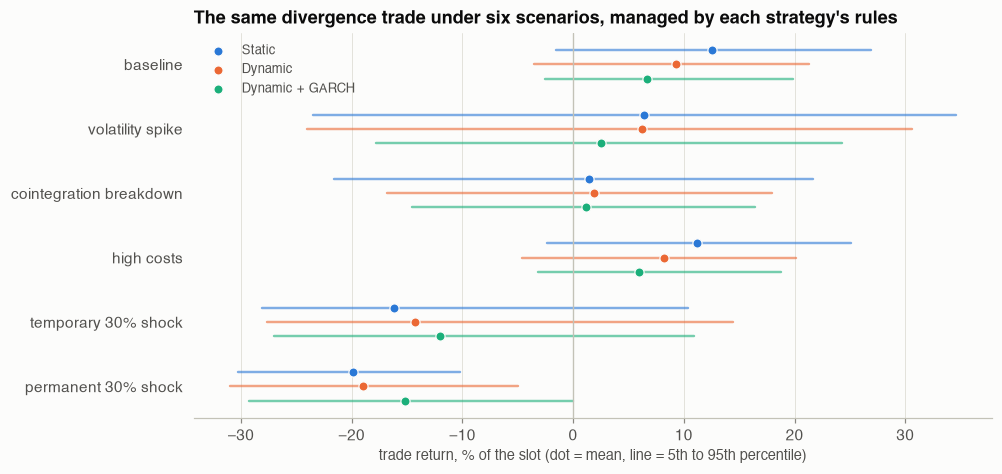

In [5]:
scen = list(SCENARIOS)
fig, ax = plt.subplots(figsize=(9, 4.2))
for j, strat in enumerate(STRATEGIES):
    for i, sc in enumerate(scen):
        x = B[(B.scenario == sc) & (B.strategy == strat)].trade_return * 100
        y = i + (j - 1) * 0.22
        ax.plot([x.quantile(.05), x.quantile(.95)], [y, y], color=P.C[j], lw=1.6, alpha=0.6)
        ax.scatter(x.mean(), y, color=P.C[j], s=36, zorder=3, edgecolor=P.SURFACE, linewidth=0.8,
                   label=strat if i == 0 else None)
LBL = {"baseline": "baseline", "vol_spike": "volatility spike", "breakdown": "cointegration breakdown",
       "high_costs": "high costs", "shock_temporary": "temporary 30% shock", "shock_permanent": "permanent 30% shock"}
ax.set_yticks(range(len(scen)), [LBL[x] for x in scen]); ax.invert_yaxis()
ax.axvline(0, color=P.AXIS, lw=0.9); ax.grid(axis="x"); ax.grid(axis="y", visible=False)
ax.set_xlabel("trade return, % of the slot (dot = mean, line = 5th to 95th percentile)")
ax.set_title("The same divergence trade under six scenarios, managed by each strategy's rules")
ax.legend(loc="upper left", fontsize=8.5)
P.save(fig, "05_position_level")

### Stop-losses under temporary vs permanent shocks

A stop-loss turns a temporary shock into a realised loss but protects against a permanent one. To see that trade-off, rerun the position-level test with the stop removed (static rules; the dynamic rules still have the OU time stop).

In [6]:
A2, B2 = monte_carlo(dgp, n_paths=N_PATHS, seed=7, n_jobs=2,
                     scenarios=("baseline", "breakdown", "shock_temporary", "shock_permanent"), position_stop=None)
cmp = pd.concat({"stop at 4 s.d.": B[B.scenario.isin(B2.scenario.unique())], "no stop": B2})
cmp = cmp.reset_index(level=0).rename(columns={"level_0": "rule"})
stop_tab = cmp.groupby(["scenario", "strategy", "rule"]).trade_return.agg(
    mean="mean", p_loss=lambda x: (x < 0).mean(), es95=lambda x: -x[x <= x.quantile(.05)].mean()).unstack("rule")
stop_tab

mean                 p_loss                   es95               
rule                            no stop stop at 4 s.d. no stop stop at 4 s.d. no stop stop at 4 s.d.
scenario        strategy                                                                            
baseline        Dynamic           0.094          0.093   0.102          0.110   0.061          0.073
                Dynamic + GARCH   0.068          0.067   0.110          0.114   0.047          0.055
                Static            0.136          0.125   0.024          0.058   0.070          0.100
breakdown       Dynamic           0.016          0.019   0.388          0.390   0.277          0.215
                Dynamic + GARCH   0.012          0.012   0.340          0.338   0.196          0.183
                Static            0.012          0.015   0.296          0.422   0.570          0.312
shock_permanent Dynamic          -0.119         -0.189   0.916          0.968   0.388          0.377
                Dynamic + GARCH  -0.101         -0.151   0.752          0.778   0.306          0.331
                Static           -0.125         -0.199   0.820          0.966   0.591          0.377
shock_temporary Dynamic           0.035         -0.143   0.342          0.836   0.258          0.354
                Dynamic + GARCH   0.005         -0.120   0.368          0.700   0.234          0.306
                Static            0.129         -0.161   0.040          0.886   0.133          0.329

## A. Strategy level: each strategy with its own entries

Here strategies decide for themselves whether and when to trade, so how often they are exposed when the shock hits is part of the result. Returns are on the capital of one pair slot over the 180 trading days.

In [7]:
strat = summarize_strategies(A)
strat

mean return, 180d  mean return after shock  P(loss after shock)  VaR95 after shock  ES95 after shock  mean max drawdown  trades per path  open at shock  \
scenario        strategy                                                                                                                                                                   
baseline        Static                       0.145                1.354e-01                0.068              0.024             0.203             -0.080            1.452          0.390   
                Dynamic                      0.024                2.150e-02                0.074              0.022             0.062             -0.028            0.620          0.112   
                Dynamic + GARCH              0.018                1.698e-02                0.080              0.022             0.061             -0.022            0.522          0.084   
vol_spike       Static                       0.146                1.352e-01                0.164              0.230             0.377             -0.125            2.110          0.390   
                Dynamic                      0.031                2.738e-02                0.156              0.129             0.234             -0.060            0.888          0.112   
                Dynamic + GARCH              0.010                8.883e-03                0.108              0.079             0.138             -0.028            0.498          0.084   
breakdown       Static                       0.005               -3.322e-03                0.362              0.260             0.374             -0.118            1.314          0.390   
                Dynamic                      0.004                1.302e-03                0.152              0.076             0.132             -0.032            0.524          0.112   
                Dynamic + GARCH              0.002                4.382e-04                0.140              0.068             0.125             -0.026            0.448          0.084   
high_costs      Static                       0.121                1.164e-01                0.082              0.049             0.242             -0.084            1.452          0.390   
                Dynamic                      0.018                1.714e-02                0.104              0.031             0.072             -0.029            0.620          0.112   
                Dynamic + GARCH              0.014                1.354e-02                0.104              0.034             0.070             -0.024            0.522          0.084   
shock_temporary Static                       0.034                2.398e-02                0.274              0.227             0.324             -0.133            1.796          0.390   
                Dynamic                     -0.012               -1.468e-02                0.126              0.199             0.243             -0.038            0.342          0.112   
                Dynamic + GARCH             -0.010               -1.174e-02                0.098              0.183             0.229             -0.029            0.288          0.084   
shock_permanent Static                      -0.102               -1.092e-01                0.534              0.356             0.448             -0.157            1.334          0.390   
                Dynamic                     -0.017               -2.013e-02                0.140              0.211             0.259             -0.039            0.324          0.112   
                Dynamic + GARCH             -0.014               -1.586e-02                0.114              0.193             0.242             -0.029            0.272          0.084   

                                 recovered by day 180 (if hit)  
scenario        strategy                                        
baseline        Static                                   0.984  
                Dynamic                                  0.890  
            

## Reading the simulations

*(Figures quoted from the tables above; position level unless stated.)*

**Baseline: when cointegration is real, all three strategies make money.** The same divergence trade earns +12.5% of its slot on average under the static rules, +9.4% under the dynamic rules and +6.8% with the filter, and loses in only 6–11% of paths. The +12.5%, +9.4% and +6.8% means are the position-level comparison: each strategy is handed the same open trade. The strategy-level table lets each rule choose its own entries. The residual in the baseline is stationary by construction. A profit there checks the exits under that assumption. It does not establish a profit on the Coin Metrics panel, and it does not certify the implementation. The filter has a cost here: it skips 20% of trades and closes another 19% early, simply because ordinary market volatility crossed its threshold.

**Volatility spike.** Swings three times wider push a quarter to a third of unfiltered trades into the stop, and about a third of trades lose. The spread still reverts, though, so the average trade still makes about +6.5%. The filter recognises this scenario and closes 54% of its positions. That cuts the expected shortfall of the worst 5% of trades from about 39% to 26% of the slot and halves the average worst mark-to-market (−6.2% → −3.2%), at the cost of most of the upside (mean +2.6% instead of +6.4%).

**Cointegration breakdown.** The spread no longer has a home, and about 40% of trades lose. The static rules have no time limit and hold trades for 35 days on average until the stop or the end of the period. The dynamic rules' OU time stop exits 43% of trades after three half-lives, which trims the tail (ES95 22% vs 30%). The filter lowers it further (18%), but only because it happens to skip or close trades during unrelated volatility episodes, not because it detects the breakdown.

**Single-coin shocks hurt most.** A 30% move in one coin is about 3 spread standard deviations. With the entry at 2 s.d., the 4σ stop fires almost immediately (81–94% of trades), and the average trade loses 16–21% of its slot (13–16% with the filter) whether the shock later reverses or not. **The GARCH flag does not monitor the spread.** It can miss an idiosyncratic move until that move appears in the factor. Its lower loss rate (72–78% vs 86–98%) comes almost entirely from the 20% of trades it skipped for unrelated reasons.

**The stop-loss trade-off.** Without a stop, the temporary shock is harmless: the static rules' trade recovers and earns +13% on average, losing in only 4% of paths. The permanent shock is a different story. Its *average* loss is smaller without a stop (−13% vs −21%, because the stop sells at the worst moment), but the worst 5% of outcomes average a 58% loss of the slot instead of 37%. Breakdowns show the same pattern (ES95 57% without a stop vs 30% with one). A stop-loss is insurance against the tail of permanent breaks, paid for by giving up the rebound after temporary shocks. In real time the two cannot be told apart.

**Higher costs** (40 bp per side, 30%/yr short fee) take about 1 percentage point (0.8–1.3) off the average trade without changing the ranking.

**Strategy level (table A).** When the strategies choose their own entries, the cointegration gate keeps the dynamic versions out of most paths: they are open at the shock only 8–11% of the time, against 40% for the static rules. That is why the static strategy takes the largest losses in the permanent-shock scenario (−11% over 180 days, with a loss in 55% of paths), while the dynamic versions lose about 2%.

**Bottom line.** The GARCH filter is a reasonable defence against *market-wide* volatility. It is no defence against what actually breaks a pair: one coin collapsing or decoupling, as XMR and ZEC did (notebook 4). Those risks need pair-level controls, such as stops, OU-based time stops, caps on exposure to any single coin, and spread-level volatility or change-point monitoring.